In [1]:
# Install the libraries required for the assignment
%pip install -q pandas numpy scikit-learn statsmodels matplotlib seaborn

Note: you may need to restart the kernel to use updated packages.


In [2]:
# Import the required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (
    accuracy_score, confusion_matrix, classification_report,
    roc_auc_score, precision_score, recall_score
)

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 160)

SEED = 910
ENROLLMENT = "s24cseu0910"

print("Enrollment:", ENROLLMENT)
print("Random seed:", SEED)
print("CPU-only experiment")

Enrollment: s24cseu0910
Random seed: 910
CPU-only experiment


In [3]:
# Load the COMPAS dataset
url = "https://github.com/propublica/compas-analysis/raw/master/compas-scores-two-years.csv"
df = pd.read_csv(url)

print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())
display(df.head())

Dataset shape: (7214, 53)
Columns: ['id', 'name', 'first', 'last', 'compas_screening_date', 'sex', 'dob', 'age', 'age_cat', 'race', 'juv_fel_count', 'decile_score', 'juv_misd_count', 'juv_other_count', 'priors_count', 'days_b_screening_arrest', 'c_jail_in', 'c_jail_out', 'c_case_number', 'c_offense_date', 'c_arrest_date', 'c_days_from_compas', 'c_charge_degree', 'c_charge_desc', 'is_recid', 'r_case_number', 'r_charge_degree', 'r_days_from_arrest', 'r_offense_date', 'r_charge_desc', 'r_jail_in', 'r_jail_out', 'violent_recid', 'is_violent_recid', 'vr_case_number', 'vr_charge_degree', 'vr_offense_date', 'vr_charge_desc', 'type_of_assessment', 'decile_score.1', 'score_text', 'screening_date', 'v_type_of_assessment', 'v_decile_score', 'v_score_text', 'v_screening_date', 'in_custody', 'out_custody', 'priors_count.1', 'start', 'end', 'event', 'two_year_recid']


,id,name,first,last,compas_screening_date,sex,dob,age,age_cat,race,juv_fel_count,decile_score,juv_misd_count,juv_other_count,priors_count,days_b_screening_arrest,c_jail_in,c_jail_out,c_case_number,c_offense_date,c_arrest_date,c_days_from_compas,c_charge_degree,c_charge_desc,is_recid,r_case_number,r_charge_degree,r_days_from_arrest,r_offense_date,r_charge_desc,r_jail_in,r_jail_out,violent_recid,is_violent_recid,vr_case_number,vr_charge_degree,vr_offense_date,vr_charge_desc,type_of_assessment,decile_score.1,score_text,screening_date,v_type_of_assessment,v_decile_score,v_score_text,v_screening_date,in_custody,out_custody,priors_count.1,start,end,event,two_year_recid
0,1,miguel hernandez,miguel,hernandez,2013-08-14,Male,1947-04-18,69,Greater than 45,Other,0,1,0,0,0,-1.0,2013-08-13 06:03:42,2013-08-14 05:41:20,13011352CF10A,2013-08-13,NaN,1.0,F,Aggravated Assault w/Firearm,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,Risk of Recidivism,1,Low,2013-08-14,Risk of Violence,1,Low,2013-08-14,2014-07-07,2014-07-14,0,0,327,0,0
1,3,kevon dixon,kevon,dixon,2013-01-27,Male,1982-01-22,34,25 - 45,African-American,0,3,0,0,0,-1.0,2013-01-26 03:45:27,2013-02-05 05:36:53,13001275CF10A,2013-01-26,NaN,1.0,F,Felony Battery w/Prior Convict,1,13009779CF10A,(F3),NaN,2013-07-05,Felony Battery (Dom Strang),NaN,NaN,NaN,1,13009779CF10A,(F3),2013-07-05,Felony Battery (Dom Strang),Risk of Recidivism,3,Low,2013-01-27,Risk of Violence,1,Low,2013-01-27,2013-01-26,2013-02-05,0,9,159,1,1
2,4,ed philo,ed,philo,2013-04-14,Male,1991-05-14,24,Less than 25,African-American,0,4,0,1,4,-1.0,2013-04-13 04:58:34,2013-04-14 07:02:04,13005330CF10A,2013-04-13,NaN,1.0,F,Possession of Cocaine,1,13011511MM10A,(M1),0.0,2013-06-16,Driving Under The Influence,2013-06-16,2013-06-16,NaN,0,NaN,NaN,NaN,NaN,Risk of Recidivism,4,Low,2013-04-14,Risk of Violence,3,Low,2013-04-14,2013-06-16,2013-06-16,4,0,63,0,1
3,5,marcu brown,marcu,brown,2013-01-13,Male,1993-01-21,23,Less than 25,African-American,0,8,1,0,1,NaN,NaN,NaN,13000570CF10A,2013-01-12,NaN,1.0,F,Possession of Cannabis,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,Risk of Recidivism,8,High,2013-01-13,Risk of Violence,6,Medium,2013-01-13,NaN,NaN,1,0,1174,0,0
4,6,bouthy pierrelouis,bouthy,pierrelouis,2013-03-26,Male,1973-01-22,43,25 - 45,Other,0,1,0,0,2,NaN,NaN,NaN,12014130CF10A,NaN,2013-01-09,76.0,F,arrest case no charge,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,Risk of Recidivism,1,Low,2013-03-26,Risk of Violence,1,Low,2013-03-26,NaN,NaN,2,0,1102,0,0


In [4]:
# Clean the data and select the required columns
required_columns = [
    "decile_score", "two_year_recid", "age",
    "priors_count", "sex", "race", "c_charge_degree"
]

missing_columns = [c for c in required_columns if c not in df.columns]
if missing_columns:
    raise ValueError(f"Missing required columns: {missing_columns}")

data = df[required_columns].copy()

data = data.replace("?", np.nan)
data["decile_score"] = pd.to_numeric(data["decile_score"], errors="coerce")
data["two_year_recid"] = pd.to_numeric(data["two_year_recid"], errors="coerce")
data["age"] = pd.to_numeric(data["age"], errors="coerce")
data["priors_count"] = pd.to_numeric(data["priors_count"], errors="coerce")

data = data[data["two_year_recid"].isin([0, 1])]
data = data[data["decile_score"].between(1, 10)]
data = data.dropna(subset=["two_year_recid", "decile_score"])

for col in ["sex", "race", "c_charge_degree"]:
    data[col] = data[col].astype("string").str.strip()
    data[col] = data[col].replace("", pd.NA)

data = data.drop_duplicates().reset_index(drop=True)

print("Original rows:", len(df))
print("Rows after target validation and duplicate removal:", len(data))
print("Missing values:")
display(data.isna().sum().to_frame("Missing count"))
print("Target distribution:")
display(data["two_year_recid"].value_counts().sort_index().to_frame("Count"))

Original rows: 7214
Rows after target validation and duplicate removal: 5876
Missing values:


,Missing count
decile_score,0
two_year_recid,0
age,0
priors_count,0
sex,0
race,0
c_charge_degree,0


Target distribution:


,Count
two_year_recid,
0,3089
1,2787


,age,priors_count,decile_score
count,5876.000000,5876.000000,5876.000000
mean,35.502383,3.962560,4.671886
std,11.872937,5.154957,2.838441
min,18.000000,0.000000,1.000000
25%,26.000000,1.000000,2.000000
50%,32.000000,2.000000,4.000000
75%,43.000000,5.000000,7.000000
max,96.000000,38.000000,10.000000


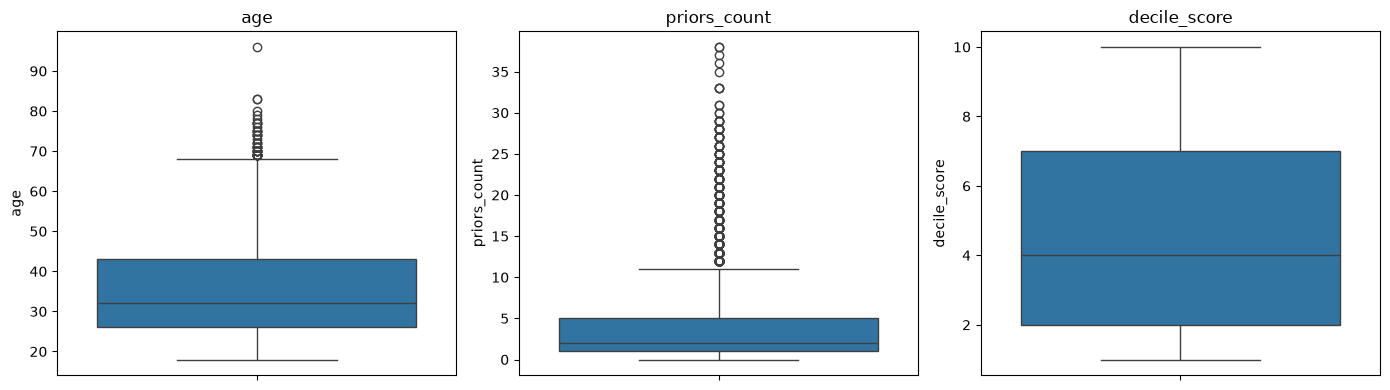

Categorical values:

sex
sex
Male      4641
Female    1235
Name: count, dtype: int64[pyarrow]

race
race
African-American    2950
Caucasian           1963
Hispanic             578
Other                335
Asian                 32
Native American       18
Name: count, dtype: int64[pyarrow]

c_charge_degree
c_charge_degree
F    3758
M    2118
Name: count, dtype: int64[pyarrow]


In [5]:
# Inspect missing values and numeric outliers
display(data[["age", "priors_count", "decile_score"]].describe())

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

for ax, col in zip(axes, ["age", "priors_count", "decile_score"]):
    sns.boxplot(data=data, y=col, ax=ax)
    ax.set_title(col)

plt.tight_layout()
plt.show()

print("Categorical values:")
for col in ["sex", "race", "c_charge_degree"]:
    print(f"\n{col}")
    print(data[col].value_counts(dropna=False))

In [6]:
# Split the data and define preprocessing pipelines
features = ["age", "priors_count", "sex", "race", "c_charge_degree"]
X = data[features]
y_score = data["decile_score"].astype(float)
y_recid = data["two_year_recid"].astype(int)

X_train, X_test, y_score_train, y_score_test, y_train, y_test = train_test_split(
    X, y_score, y_recid,
    test_size=0.30,
    random_state=SEED,
    stratify=y_recid
)

numeric_features = ["age", "priors_count"]
categorical_features = ["sex", "race", "c_charge_degree"]

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Training proportion:", round(len(X_train) / len(data), 3))
print("Testing proportion:", round(len(X_test) / len(data), 3))

Training rows: 4113
Testing rows: 1763
Training proportion: 0.7
Testing proportion: 0.3


In [7]:
# Train linear regression and logistic regression
model_a = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LinearRegression())
])

model_b = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(max_iter=2000, random_state=SEED))
])

model_a.fit(X_train, y_score_train)
model_b.fit(X_train, y_train)

linear_predictions = model_a.predict(X_test)
recid_probabilities = model_b.predict_proba(X_test)[:, 1]
recid_predictions = (recid_probabilities >= 0.5).astype(int)

print("Linear regression R²:", round(model_a.score(X_test, y_score_test), 4))
print("Logistic regression accuracy:", round(accuracy_score(y_test, recid_predictions), 4))
print("Logistic regression ROC-AUC:", round(roc_auc_score(y_test, recid_probabilities), 4))
print("\nClassification report:")
print(classification_report(y_test, recid_predictions, zero_division=0))

Linear regression R²: 0.3969
Logistic regression accuracy: 0.65
Logistic regression ROC-AUC: 0.7011

Classification report:
              precision    recall  f1-score   support

           0       0.66      0.71      0.68       927
           1       0.64      0.59      0.61       836

    accuracy                           0.65      1763
   macro avg       0.65      0.65      0.65      1763
weighted avg       0.65      0.65      0.65      1763



In [8]:
# Compare the two thresholding approaches
linear_threshold = np.median(linear_predictions)

linear_flags = (linear_predictions >= linear_threshold).astype(int)
logistic_flags = (recid_probabilities >= 0.5).astype(int)

agreement_matrix = confusion_matrix(linear_flags, logistic_flags, labels=[0, 1])
mismatch_mask = linear_flags != logistic_flags
mismatch_count = int(mismatch_mask.sum())
mismatch_percentage = mismatch_mask.mean() * 100

print("Linear prediction median:", round(linear_threshold, 4))
print("Logistic probability threshold: 0.5")
print("\nAgreement matrix (rows = linear, columns = logistic):")
display(pd.DataFrame(
    agreement_matrix,
    index=["Linear: low", "Linear: high"],
    columns=["Logistic: low", "Logistic: high"]
))

print("Mismatched cases:", mismatch_count)
print("Mismatch percentage:", round(mismatch_percentage, 2), "%")

Linear prediction median: 4.7773
Logistic probability threshold: 0.5

Agreement matrix (rows = linear, columns = logistic):


,Logistic: low,Logistic: high
Linear: low,846,35
Linear: high,154,728


Mismatched cases: 189
Mismatch percentage: 10.72 %


In [9]:
# Compare prior-conviction coefficients across race groups
formula = "two_year_recid ~ priors_count + age + C(sex) + C(race) + C(c_charge_degree)"

analysis_data = data.dropna(subset=features + ["two_year_recid"]).copy()
analysis_data["two_year_recid"] = analysis_data["two_year_recid"].astype(int)

full_subgroup_model = smf.logit(formula, data=analysis_data).fit(disp=False, maxiter=200)

race_models = {}
for group in ["African-American", "Caucasian"]:
    group_data = analysis_data[analysis_data["race"] == group]
    race_formula = "two_year_recid ~ priors_count + age + C(sex) + C(c_charge_degree)"
    race_models[group] = smf.logit(
        race_formula, data=group_data
    ).fit(disp=False, maxiter=200)

def coefficient_summary(model, variable):
    ci = model.conf_int().loc[variable]
    return {
        "Coefficient": model.params[variable],
        "CI lower": ci.iloc[0],
        "CI upper": ci.iloc[1],
        "p-value": model.pvalues[variable]
    }

subgroup_results = {
    "Full dataset": coefficient_summary(full_subgroup_model, "priors_count"),
    "African-American": coefficient_summary(race_models["African-American"], "priors_count"),
    "Caucasian": coefficient_summary(race_models["Caucasian"], "priors_count")
}

subgroup_table = pd.DataFrame(subgroup_results).T
display(subgroup_table.round(4))

,Coefficient,CI lower,CI upper,p-value
Full dataset,0.1265,0.1129,0.1400,0.0
African-American,0.1207,0.1039,0.1375,0.0
Caucasian,0.1373,0.1094,0.1651,0.0


In [10]:
# Measure coefficient changes after removing prior convictions
full_formula = "two_year_recid ~ age + priors_count + C(sex) + C(race) + C(c_charge_degree)"
reduced_formula = "two_year_recid ~ age + C(sex) + C(race) + C(c_charge_degree)"

full_ovb = smf.logit(full_formula, data=analysis_data).fit(disp=False, maxiter=200)
reduced_ovb = smf.logit(reduced_formula, data=analysis_data).fit(disp=False, maxiter=200)

common_coefficients = [
    name for name in full_ovb.params.index
    if name != "Intercept"
    and name in reduced_ovb.params.index
    and name != "priors_count"
]

ovb_table = pd.DataFrame({
    "Full coefficient": full_ovb.params[common_coefficients],
    "Reduced coefficient": reduced_ovb.params[common_coefficients]
})

ovb_table["Absolute change"] = (
    ovb_table["Reduced coefficient"] - ovb_table["Full coefficient"]
).abs()

ovb_table["Percentage change"] = np.where(
    ovb_table["Full coefficient"].abs() > 1e-8,
    ovb_table["Absolute change"] / ovb_table["Full coefficient"].abs() * 100,
    np.nan
)

ovb_table = ovb_table.sort_values("Percentage change", ascending=False)
display(ovb_table.head(10).round(4))

print("Omitted variable: priors_count")
print("Largest percentage shift:")
display(ovb_table.head(1).round(4))

,Full coefficient,Reduced coefficient,Absolute change,Percentage change
C(race)[T.Native American],0.0236,0.1449,0.1212,513.0981
C(race)[T.Caucasian],0.0585,-0.1817,0.2403,410.5913
C(race)[T.Other],-0.2529,-0.5876,0.3347,132.3686
C(c_charge_degree)[T.M],-0.1563,-0.3233,0.1670,106.8165
C(race)[T.Hispanic],-0.2792,-0.5687,0.2895,103.6934
C(race)[T.Asian],-0.5763,-1.0183,0.4420,76.6900
C(sex)[T.Male],0.3120,0.4847,0.1727,55.3574
age,-0.0408,-0.0292,0.0116,28.5225


Omitted variable: priors_count
Largest percentage shift:


,Full coefficient,Reduced coefficient,Absolute change,Percentage change
C(race)[T.Native American],0.0236,0.1449,0.1212,513.0981


In [11]:
# Extract confident but incorrect predictions
adversarial = X_test.copy()
adversarial["actual"] = y_test
adversarial["probability"] = recid_probabilities
adversarial["prediction"] = recid_predictions

adversarial["error_type"] = np.select(
    [
        (adversarial["probability"] >= 0.75) & (adversarial["actual"] == 0),
        (adversarial["probability"] <= 0.25) & (adversarial["actual"] == 1)
    ],
    ["False positive", "False negative"],
    default="Other"
)

wrong_confident = adversarial[adversarial["error_type"] != "Other"].copy()
sample_size = min(50, len(wrong_confident))

adversarial_sample = wrong_confident.sample(
    n=sample_size, random_state=SEED
) if sample_size else wrong_confident.copy()

print("Test-set size:", len(X_test))
print("Confident incorrect predictions:", len(wrong_confident))
print("Percentage of test set:", round(len(wrong_confident) / len(X_test) * 100, 2), "%")
print("Rows selected for analysis:", len(adversarial_sample))

print("\nError types:")
display(adversarial_sample["error_type"].value_counts().to_frame("Count"))

print("\nAge comparison:")
display(pd.DataFrame({
    "Full test set": X_test["age"].describe(),
    "Adversarial subset": adversarial_sample["age"].describe()
}).round(2))

print("\nGender distribution (%):")
display(pd.concat([
    X_test["sex"].value_counts(normalize=True).mul(100).rename("Full test set"),
    adversarial_sample["sex"].value_counts(normalize=True).mul(100).rename("Adversarial subset")
], axis=1).fillna(0).round(2))

print("\nPrior-conviction distribution:")
display(pd.DataFrame({
    "Full test set": X_test["priors_count"].describe(),
    "Adversarial subset": adversarial_sample["priors_count"].describe()
}).round(2))

display(adversarial_sample.head(10))

Test-set size: 1763
Confident incorrect predictions: 69
Percentage of test set: 3.91 %
Rows selected for analysis: 50

Error types:


,Count
error_type,
False negative,26
False positive,24



Age comparison:


,Full test set,Adversarial subset
count,1763.00,50.00
mean,35.60,46.68
std,11.87,13.19
min,18.00,23.00
25%,26.00,36.25
50%,32.00,49.50
75%,43.00,57.00
max,80.00,69.00



Gender distribution (%):


,Full test set,Adversarial subset
sex,,
Male,78.39,68.0
Female,21.61,32.0



Prior-conviction distribution:


,Full test set,Adversarial subset
count,1763.00,50.00
mean,4.21,8.50
std,5.35,8.67
min,0.00,0.00
25%,1.00,1.00
50%,2.00,5.50
75%,6.00,14.75
max,33.00,27.00


,age,priors_count,sex,race,c_charge_degree,actual,probability,prediction,error_type
1850,50,0,Male,Caucasian,M,1,0.246722,0,False negative
5129,40,20,Male,African-American,F,0,0.875398,1,False positive
3201,37,0,Female,Hispanic,M,1,0.210050,0,False negative
426,57,1,Male,African-American,F,1,0.243683,0,False negative
3327,51,19,Male,African-American,F,0,0.800506,1,False positive
284,44,24,Male,African-American,M,0,0.892000,1,False positive
3446,44,1,Female,Caucasian,M,1,0.244253,0,False negative
1571,37,24,Male,African-American,F,0,0.929277,1,False positive
2727,69,0,Male,Caucasian,M,1,0.134207,0,False negative
5673,34,11,Male,Caucasian,F,0,0.750143,1,False positive


In [12]:
# Compare candidate characteristics in the adversarial subset
def characteristic_summary(test, subset):
    rows = []
    for label, column, condition in [
        ("Age under 25", "age", lambda s: s < 25),
        ("At least 3 prior convictions", "priors_count", lambda s: s >= 3),
        ("At least 5 prior convictions", "priors_count", lambda s: s >= 5),
        ("Male", "sex", lambda s: s == "Male"),
        ("African-American", "race", lambda s: s == "African-American"),
        ("Caucasian", "race", lambda s: s == "Caucasian")
    ]:
        rows.append({
            "Characteristic": label,
            "Full test set (%)": condition(test[column]).mean() * 100,
            "Adversarial subset (%)": condition(subset[column]).mean() * 100
            if len(subset) else np.nan
        })
    return pd.DataFrame(rows)

display(characteristic_summary(X_test, adversarial_sample).round(2))

,Characteristic,Full test set (%),Adversarial subset (%)
0,Age under 25,17.02,4.0
1,At least 3 prior convictions,46.74,56.0
2,At least 5 prior convictions,31.76,52.0
3,Male,78.39,68.0
4,African-American,50.20,50.0
5,Caucasian,35.05,40.0


In [13]:
# Calculate fairness metrics across decision thresholds
fairness_data = X_test[["race"]].copy()
fairness_data["actual"] = y_test
fairness_data["probability"] = recid_probabilities

group_a = "African-American"
group_b = "Caucasian"
thresholds = np.round(np.arange(0.05, 0.951, 0.10), 2)

def safe_ratio(a, b):
    return a / b if pd.notna(a) and pd.notna(b) and b > 0 else np.nan

def group_metrics(group_data, threshold):
    actual = group_data["actual"].to_numpy()
    predicted = (group_data["probability"].to_numpy() >= threshold).astype(int)

    tp = np.sum((actual == 1) & (predicted == 1))
    fp = np.sum((actual == 0) & (predicted == 1))
    tn = np.sum((actual == 0) & (predicted == 0))
    fn = np.sum((actual == 1) & (predicted == 0))

    return {
        "positive_rate": predicted.mean() if len(predicted) else np.nan,
        "tpr": tp / (tp + fn) if tp + fn else np.nan,
        "fpr": fp / (fp + tn) if fp + tn else np.nan,
        "precision": tp / (tp + fp) if tp + fp else np.nan
    }

fairness_rows = []

for threshold in thresholds:
    a = group_metrics(
        fairness_data[fairness_data["race"] == group_a], threshold
    )
    b = group_metrics(
        fairness_data[fairness_data["race"] == group_b], threshold
    )

    dp = safe_ratio(a["positive_rate"], b["positive_rate"])
    tpr_ratio = safe_ratio(a["tpr"], b["tpr"])
    fpr_ratio = safe_ratio(a["fpr"], b["fpr"])
    eo = min(tpr_ratio, fpr_ratio) if pd.notna(tpr_ratio) and pd.notna(fpr_ratio) else np.nan
    pp = safe_ratio(a["precision"], b["precision"])

    fairness_rows.append({
        "Threshold": threshold,
        "DP": dp,
        "TPR ratio": tpr_ratio,
        "FPR ratio": fpr_ratio,
        "EO": eo,
        "PP": pp,
        "Accuracy": accuracy_score(
            fairness_data["actual"],
            (fairness_data["probability"] >= threshold).astype(int)
        )
    })

fairness_table = pd.DataFrame(fairness_rows)
display(fairness_table.round(4))

,Threshold,DP,TPR ratio,FPR ratio,EO,PP,Accuracy
0,0.05,1.0000,1.0000,1.0000,1.0000,1.1555,0.4742
1,0.15,1.0186,1.0051,1.0293,1.0051,1.1402,0.4838
2,0.25,1.0664,1.0506,1.0721,1.0506,1.1384,0.5235
3,0.35,1.1349,1.1080,1.1330,1.1080,1.1280,0.5859
4,0.45,1.3137,1.2664,1.2901,1.2664,1.1139,0.6319
5,0.55,1.6209,1.4353,1.7660,1.4353,1.0232,0.6455
6,0.65,1.8680,1.6567,2.0000,1.6567,1.0248,0.6086
7,0.75,2.2146,1.9250,2.5000,1.9250,1.0043,0.5735
8,0.85,3.6312,3.3995,2.8000,2.8000,1.0817,0.5508
9,0.95,NaN,NaN,NaN,NaN,NaN,0.5281


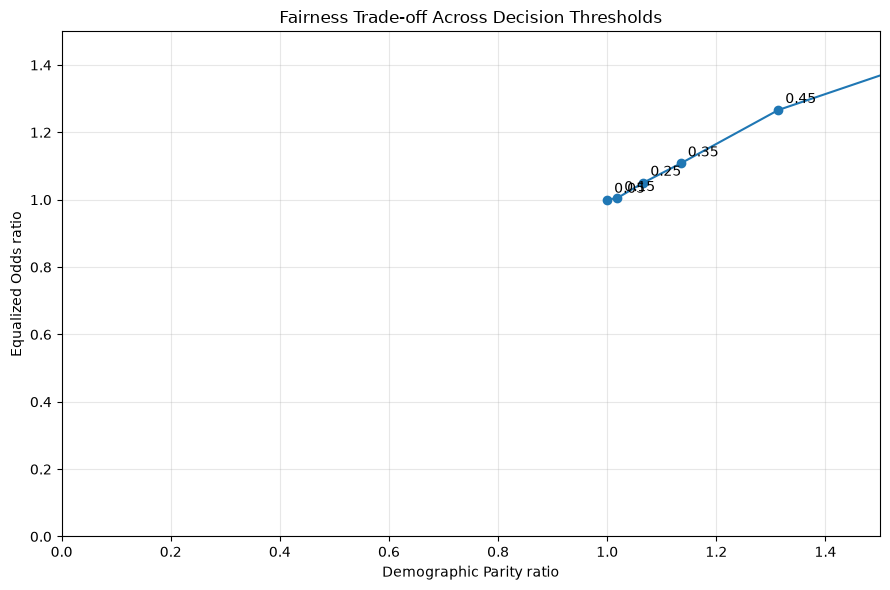

In [14]:
# Plot demographic parity against equalized odds
plot_data = fairness_table.dropna(subset=["DP", "EO"])

plt.figure(figsize=(9, 6))
plt.plot(plot_data["DP"], plot_data["EO"], marker="o")

for _, row in plot_data.iterrows():
    plt.annotate(
        f'{row["Threshold"]:.2f}',
        (row["DP"], row["EO"]),
        xytext=(5, 5),
        textcoords="offset points"
    )

plt.xlim(0, 1.5)
plt.ylim(0, 1.5)
plt.xlabel("Demographic Parity ratio")
plt.ylabel("Equalized Odds ratio")
plt.title("Fairness Trade-off Across Decision Thresholds")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [15]:
# Compare fairness metrics at the most and least favorable observed thresholds
valid_rows = fairness_table.dropna(subset=["DP", "EO", "PP"])

if len(valid_rows):
    dp_best_index = (valid_rows["DP"] - 1).abs().idxmin()
    eo_best_index = (valid_rows["EO"] - 1).abs().idxmin()

    print("Threshold closest to demographic parity:")
    display(fairness_table.loc[[dp_best_index]].round(4))

    print("Threshold closest to equalized odds:")
    display(fairness_table.loc[[eo_best_index]].round(4))

    print("All threshold results:")
    display(fairness_table.round(4))
else:
    print("No thresholds have all three defined fairness ratios.")

Threshold closest to demographic parity:


,Threshold,DP,TPR ratio,FPR ratio,EO,PP,Accuracy
0,0.05,1.0,1.0,1.0,1.0,1.1555,0.4742


Threshold closest to equalized odds:


,Threshold,DP,TPR ratio,FPR ratio,EO,PP,Accuracy
0,0.05,1.0,1.0,1.0,1.0,1.1555,0.4742


All threshold results:


,Threshold,DP,TPR ratio,FPR ratio,EO,PP,Accuracy
0,0.05,1.0000,1.0000,1.0000,1.0000,1.1555,0.4742
1,0.15,1.0186,1.0051,1.0293,1.0051,1.1402,0.4838
2,0.25,1.0664,1.0506,1.0721,1.0506,1.1384,0.5235
3,0.35,1.1349,1.1080,1.1330,1.1080,1.1280,0.5859
4,0.45,1.3137,1.2664,1.2901,1.2664,1.1139,0.6319
5,0.55,1.6209,1.4353,1.7660,1.4353,1.0232,0.6455
6,0.65,1.8680,1.6567,2.0000,1.6567,1.0248,0.6086
7,0.75,2.2146,1.9250,2.5000,1.9250,1.0043,0.5735
8,0.85,3.6312,3.3995,2.8000,2.8000,1.0817,0.5508
9,0.95,NaN,NaN,NaN,NaN,NaN,0.5281


In [16]:
# Save computed results for the final report
agreement_table = pd.DataFrame(
    agreement_matrix,
    index=["Linear: low", "Linear: high"],
    columns=["Logistic: low", "Logistic: high"]
)

agreement_table.to_csv("part1_agreement_matrix.csv")
subgroup_table.to_csv("part2_1_subgroup_coefficients.csv")
ovb_table.to_csv("part2_2_omitted_variable_bias.csv")
adversarial_sample.to_csv("part2_3_adversarial_subset.csv", index=True)
fairness_table.to_csv("part2_4_fairness_metrics.csv", index=False)

model_summary = pd.DataFrame([{
    "Enrollment": ENROLLMENT,
    "Random seed": SEED,
    "Dataset rows": len(data),
    "Training rows": len(X_train),
    "Test rows": len(X_test),
    "Linear regression test R2": model_a.score(X_test, y_score_test),
    "Logistic accuracy at 0.5": accuracy_score(y_test, recid_predictions),
    "Logistic ROC-AUC": roc_auc_score(y_test, recid_probabilities),
    "Linear threshold": linear_threshold,
    "Mismatch count": mismatch_count,
    "Mismatch percentage": mismatch_percentage,
    "Confident incorrect count": len(wrong_confident)
}])

model_summary.to_csv("part1_model_summary.csv", index=False)
display(model_summary.round(4))

print("Saved CSV files:")
print("part1_model_summary.csv")
print("part1_agreement_matrix.csv")
print("part2_1_subgroup_coefficients.csv")
print("part2_2_omitted_variable_bias.csv")
print("part2_3_adversarial_subset.csv")
print("part2_4_fairness_metrics.csv")

,Enrollment,Random seed,Dataset rows,Training rows,Test rows,Linear regression test R2,Logistic accuracy at 0.5,Logistic ROC-AUC,Linear threshold,Mismatch count,Mismatch percentage,Confident incorrect count
0,s24cseu0910,910,5876,4113,1763,0.3969,0.65,0.7011,4.7773,189,10.7204,69


Saved CSV files:
part1_model_summary.csv
part1_agreement_matrix.csv
part2_1_subgroup_coefficients.csv
part2_2_omitted_variable_bias.csv
part2_3_adversarial_subset.csv
part2_4_fairness_metrics.csv
